# DNA Structure Generation Tutorial

Thor van Heesch (T.vanHeesch@uva.nl) and Jocelyne Vreede (J.Vreede@uva.nl)

van 't Hoff Institute for Molecular Sciences, University of Amsterdam

===

The code in this tutorial is based on `MDNA`, using rigid body representations for base pairs. 

To go through the tutorial, run each cell with code, using either shift-enter or the play button. 


This notebook will guide you through various ways to generate and manipulate DNA structures. You'll learn to:
- Generate DNA structures from scratch.
- Use custom sequences and define DNA topology to manipulate the linking number
- Apply custom shapes using control points
- Visualize and save DNA structures.


### A disclaimer 

The mdna software contains experimental code developed by Jocelyne’s research group. This code facilitates the analysis and generation of DNA structures and ensembles. If anything is unclear or does not work as expected, do not feel discouraged. Instead, please reach out, and we are happy to help! In principle, you do not have to read up on mdna. However, if you are curious, feel free to explore its contents: 

[Documentation](https://heezch.github.io/mdna/)

[Publication](https://academic.oup.com/nar/article/54/10/gkag549/8699744)

Start with importing required libraries, by running the cell (shift-enter, or the 'play' button). The brackets next to the cell will change from [] to [*] (running) to [1] (done). The number in the brackets indicates the order in which you executed cells. 

In [1]:
# The solutions are in the solutions/ folder: run them from the main folder, where data/ and devtools/ are
import os
if os.path.basename(os.getcwd()) == 'solutions':
    os.chdir('..')

In [2]:
import numpy as np
import mdtraj as md
import matplotlib.pyplot as plt
import seaborn as sns

import devtools.mdna_workarounds  # fixes for known issues in mdna 0.2.0, see devtools/mdna_workarounds.py
import mdna
from devtools.viewer import view  # 3D viewer inside the notebook, see devtools/viewer.py

## Linear DNA Structure Generation
We start by generating linear DNA structures. First use default settings, which produces a DNA structure with the sequence known as the Drew Dickerson dodecamer.

==

Original reference [Drew et al. PNAS 1981](https://www.pnas.org/doi/10.1073/pnas.78.4.2179?url_ver=Z39.88-2003&rfr_id=ori%3Arid%3Acrossref.org&rfr_dat=cr_pub++0pubmed). 

In [3]:
dna = mdna.make()
dna.describe()
dna.save_pdb('./drew_dickerson')

Default sequence: CGCGAATTCGCG
Number of base pairs: 12 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 12

DNA structure with 12 base pairs
Sequence: CGCGAATTCGCG
Trajectory not loaded
Frames:  (12, 1, 4, 3)


Visualize the structure you just generated, first using the `dna.draw()` function and then in 3D with `view(dna)`. You can also open the PDB file in a molecular viewer, such as VMD, pymol or molstarviewer. In the 3D viewer, find the second base pair (residue index 1 and 22) and highlight it. 

`view(dna)` shows the structure in 3D, inside the notebook. Drag with the left mouse button to rotate, with the right mouse button to pan, and scroll to zoom. The viewer loads Mol* from the internet, so you need a connection.

<IPython.core.display.Javascript object>

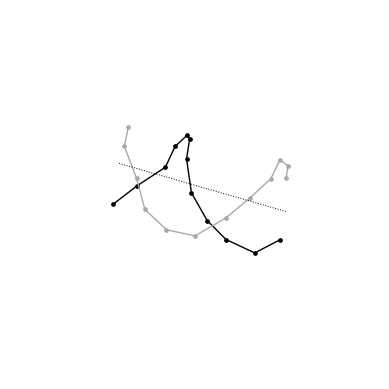

In [4]:
dna.draw()
view(dna)

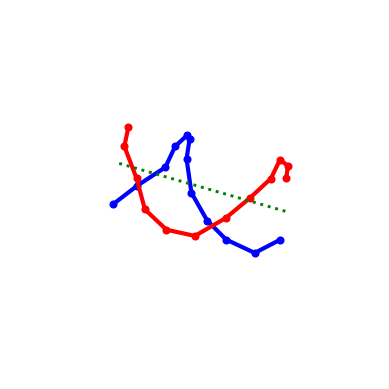

In [5]:
# Change styling
dna.draw(backbone=True, triads=False, helical_axis=True, lw=3, markersize=4, color_anti='red', color_lead='blue', color_axis='green')

### Specifying a Sequence
You can specify a DNA sequence directly when generating the structure. 

In [6]:
dna = mdna.make(sequence='GCGCGCGCGC')
dna.describe()
dna.save_pdb('./GCGCGCGCGC')


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 10

DNA structure with 10 base pairs
Sequence: GCGCGCGCGC
Trajectory not loaded
Frames:  (10, 1, 4, 3)


### Specify the length
You can specify the length of a DNA sequence, in number of base pairs, when generating the structure. If no sequence is provided, a random sequence will be generated. 

In [7]:
dna = mdna.make(n_bp=20)
dna.describe()
dna.save_pdb('./random_20bp')

Random sequence: ATTACCCACTCTAGACAGGA 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 20

DNA structure with 20 base pairs
Sequence: ATTACCCACTCTAGACAGGA
Trajectory not loaded
Frames:  (20, 1, 4, 3)


### Do it yourself!
Make DNA of length 12, 24 and 48 base pairs. Without a sequence, mdna picks a random sequence of A, C, G and T. What is the number of complete turns for each length? 

In [8]:
# Add length
length = [12, 24, 48]
for l in length:
    dna_l = mdna.make(n_bp=l)
    dna_l.describe()
    dna_l.save_pdb(f'./dna_length_{l}')
    print(f'{l} bp = {l / 10.5:.2f} turns\n')

Random sequence: ATGTCGGGGCAT 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 12

DNA structure with 12 base pairs
Sequence: ATGTCGGGGCAT
Trajectory not loaded
Frames:  (12, 1, 4, 3)
12 bp = 1.14 turns

Random sequence: ATATTGTAACGCCAGTCTTTTTGA 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 24

DNA structure with 24 base pairs
Sequence: ATATTGTAACGCCAGTCTTTTTGA
Trajectory not loaded
Frames:  (24, 1, 4, 3)
24 bp = 2.29 turns

Random sequence: ACTAACGTTACGTCAAGACCAACCGGTCTTGGGCGGATTTTTTTCGTT 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Sp

B-DNA has 10.5 base pairs per turn. 12 bp is 1.14 turns (1 complete turn), 24 bp is 2.29 turns (2 complete turns) and 48 bp is 4.57 turns (4 complete turns).

### Modify the sequence of a structure
The function `mutate()` can alter the sequence of a structure. First generate a structure with a specific sequence, and then mutate the first base (position 0) to guanine G and the second (position 1) to adenine A. Note that here, the mdna object is called `dna_mutate` instead of `dna`. First go through the example, and then mutate the random sequence by changing all adenines to guanine and vice versa. 

In [9]:
dna_mutate = mdna.make(sequence='AGCGATATAGA')
dna_mutate.describe()
dna_mutate.save_pdb('./AGCGATATAGA')

#first base is G, second base is A
mutations = {0:'G', 1:'A'}

dna_mutate.mutate(mutations)

dna_mutate.describe()
dna_mutate.save_pdb('./mutant')


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 11

DNA structure with 11 base pairs
Sequence: AGCGATATAGA
Trajectory not loaded
Frames:  (11, 1, 4, 3)


DNA structure with 11 base pairs
Sequence: GACGATATAGA
Trajectory: <mdtraj.Trajectory with 1 frames, 451 atoms, 22 residues, without unitcells>
Frames not loaded


In [10]:
#mutate the random sequence
#get the sequence
dna.describe()

# swap every A for G and every G for A
swap = {'A': 'G', 'G': 'A'}
mutations = {i: swap[b] for i, b in enumerate(dna.sequence) if b in swap}

#perform the mutation
dna.mutate(mutations)

#check
dna.describe()

#visualize / save coordinates
dna.save_pdb('./random_20bp_mutated')

DNA structure with 20 base pairs
Sequence: ATTACCCACTCTAGACAGGA
Trajectory: <mdtraj.Trajectory with 1 frames, 820 atoms, 40 residues, without unitcells>
Frames:  (20, 1, 4, 3)


DNA structure with 20 base pairs
Sequence: GTTGCCCGCTCTGAGCGAAG
Trajectory: <mdtraj.Trajectory with 1 frames, 820 atoms, 40 residues, without unitcells>
Frames not loaded


### Do it yourself!

It is your turn now. Make new cells and use the code provided above as inspiration for the following questions:

a. Visualize the structure you generated with the sequence `GCGCGCGCGC`. The pdb file is stored as `GCGCGCGCGC.pdb`. 

b. Which sequence did you generate for the random 20 base pairs? Visualize the structure. The file is stored as `random_20bp.pdb`. 

c. In the structure you generated for b, mutate all adenines to guanine and all guanines to adenine. Visualize the structure. 

d. Generate a structure with sequence ATCGATCGATCGATCGATCG and visualize this structure. 

For visualization, use both the `.draw` function and a molecular visualizer.  Note that if you want to use a visualizer outside this notebook, you will need to save the pdb file with `.save_pdb()`.

In [11]:
# a. the structure with sequence GCGCGCGCGC (also saved as GCGCGCGCGC.pdb)
gcgc = mdna.make(sequence='GCGCGCGCGC')
view(gcgc)

# b. and c. are done in the cells above: describe() prints the random sequence,
# and the structures are saved as random_20bp.pdb and random_20bp_mutated.pdb
view(dna)

# d.
atcg = mdna.make(sequence='ATCGATCGATCGATCGATCG')
view(atcg)
atcg.save_pdb('./ATCGATCGATCGATCGATCG')


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 10



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 20



<IPython.core.display.Javascript object>

## Modify the twist

The twist can be adjusted by changing the number of basepairs per turn: `bp_per_turn`. For regular B-DNA, the number of base pairs per turn is 10.5. 

The default twist per base is `360/bp_per_turn` = `34.3`. A larger twist per base pair overwinds the DNA, and a smaller one underwinds it. For `bp_per_turn` it works the other way around: fewer base pairs per turn means more twist per base pair. So `bp_per_turn=5` (72 degrees per base pair) gives overwound DNA. 

You can make and visualize underwound and overwound DNA by adjusting the code below. 

In [12]:
sequence='CGCGATTTCGCGCGCGATTTCGCG'
default_twist = mdna.make(sequence=sequence)
default_twist.save_pdb('./default_twist')

over_twist = mdna.make(sequence=sequence, bp_per_turn=5)
over_twist.save_pdb('./over_twist')

under_twist = mdna.make(sequence=sequence, bp_per_turn=15)
under_twist.save_pdb('./under_twist')



Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 24


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 24


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 24



## Curved DNA

To construct curved DNA, we use a parametric function in three dimensions. The curve is defined by three functions, one for each dimension (x, y, z). 

Let's define a spiral parametric function depending on a single parameter `t`:

In [13]:
def parametric_spiral(t, radius=5):
    x = np.cos(t)*radius
    y = np.sin(t)*radius
    z = t
    return x, y, z

Now, generate a range of values for `t`, from 0 to 3π with 100 points. For each value of `t`, `x`, `y`, and `z` coordinates are computed using the parametric function: 

In [14]:
t = np.linspace(0, 3 * np.pi, 100)
x, y, z = parametric_spiral(t)

Plot the three dimensional spiral curve:

Text(0.5, 0, 'Z')

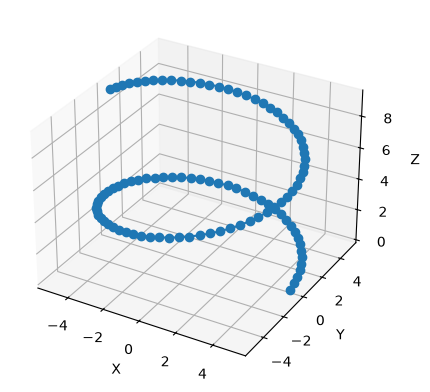

In [15]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, 'o-')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

The x,y,z coordinates can be used to construct a spline, a smooth curve through the control points, i.e. the x,y,z coordinates of the spiral. 

The coordinates are in nanometres. mdna places a base pair every 0.34 nm along the curve, so the length of the curve sets how many base pairs fit. 

In [16]:
control_points = np.array([x, y, z]).T  
spiral = mdna.make(control_points=control_points)

Random sequence: TAACTCATACTGCAATAATAGCGACACGACTGGGAGAAGTTAATTGGATTGGTGCGGACGACTATGACCCGTGGACAATATTGGTGGAATAGTCTGGTTTGCGCTTGAGAGAGAACGACCTATAACGGACAAGACCCGGACC 



With the `.draw()` function, you can visualize the spline as well. Each points represents a basepair. 

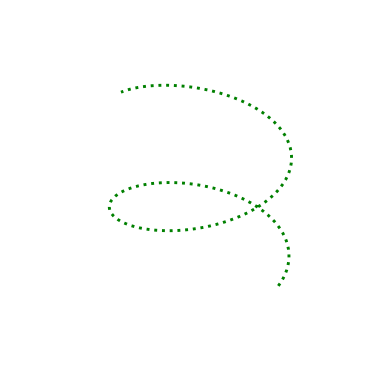

In [17]:
spiral.draw(backbone=False, helical_axis=True, lw=3, color_axis='green')

Each point has an orthonormal basis, the rigid body reference frame for each basepair. 

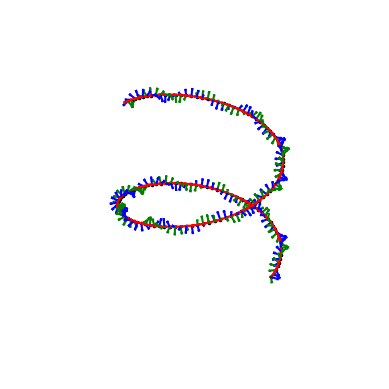

In [18]:
spiral.draw(backbone=False, triads=True, length=0.5)

 These reference frames provide a position and mapping to construct the positions of atoms in DNA base pairs.  With the `.make()` function that you have used before, atomic positions are generated using the reference frames. In the next (default) visualization, the backbone phosphorus atoms are shown, as well as the spline. 

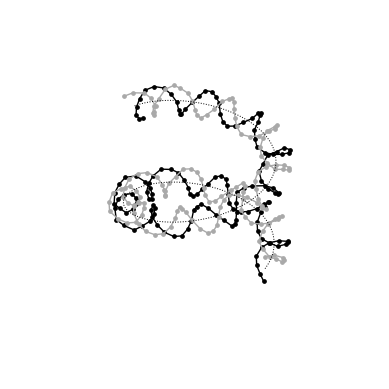

In [19]:
spiral.draw()

Visualize the spiral in a molecular viewer after save the coordinates in a pdb file: 

In [20]:
spiral.save_pdb('./spiral')
view(spiral)

<IPython.core.display.Javascript object>

## Set your own control points

Alternatively, you can define the spline using control points you set yourself. At least 4 control points are required to construct a spline, and you can add as many as you want. Control points need to be defined as Cartesian coordinates, in nanometres, stored in a numpy array: 

`control_points = np.array([[0,0,0],[6,-3,3],[6,3,6],[0,0,9],[-6,-3,6],[-6,3,3]])`. This will generate a curved sequence of DNA. 

In [21]:
control_points = np.array([[0,0,0],[6,-3,3],[6,3,6],[0,0,9],[-6,-3,6],[-6,3,3]])
spline = mdna.make(control_points=control_points)

Random sequence: ACGCGAGGCCCTCGGCCTTAGGCAATGGGGTAGACCTAGGCAAAGAGGACGTGGTCTTGCGTTCTCCTGGATGTCGCGGCTAAGTAAGGATGCCGAGCTTGGTGTACTAGTCGACAG 



Plot the control points:

Text(0.5, 0, 'Z')

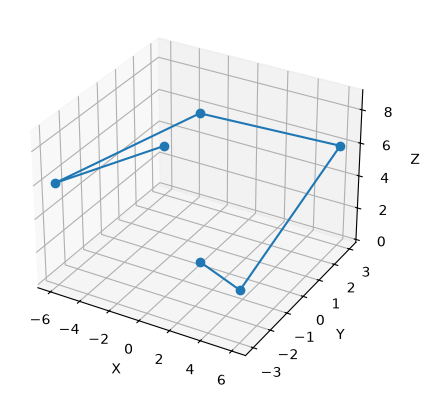

In [22]:
# plot the control points
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(*control_points.T, 'o-')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

Determine how many basepairs fit along the spline: 

Number of base pairs is 117 that fit along the spline.


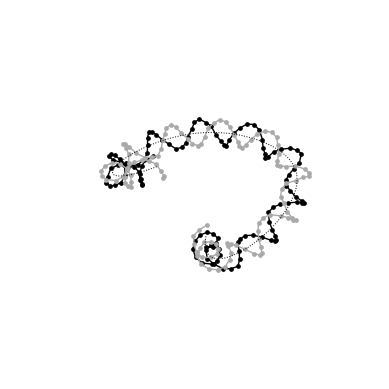

In [23]:
n_bp = spline.n_bp
print(f'Number of base pairs is {n_bp} that fit along the spline.')
spline.draw()

Visualize the spline-based structure: 

In [24]:
spline.save_pdb('./spline')
view(spline)

<IPython.core.display.Javascript object>

### Do it yourself!

Play around with the control points to create different curves. 

## Closed loops


Using `closed_spline = mdna.make(control_points=control_points,circular=True)` will create a closed loop, provided the first and last control points are the same. In the following code, the curve from the previous section is closed. 

Note that the code is now combined into one cell and that the plotting of the control points is now skipped. 


Structure is requested to be circular:
	Excess twist per base to make ends meet: 0.96 degrees
	New twist angle per base pair: 35.24 

Random sequence: TTTATTTTATCTAGTCTATGTGCCGATCTAGAAGCAGCTTGCGTGCCTTACTCAAGGTAACTGTGGCGAGTCGTAATGACTAGCATAATGGTATGTTACATCACGTTTGTAGGACACCTGTGCTTTTACACCCCGTCCCGTTG 

Number of base pairs is 143 that fit along the spline.


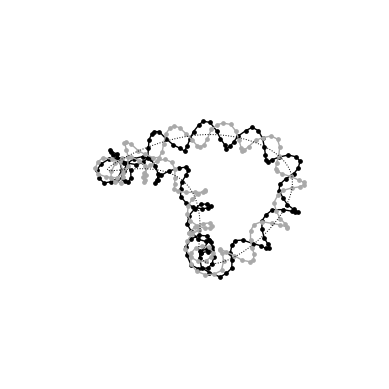

In [25]:
control_points = np.array([[0,0,0],[6,-3,3],[6,3,6],[0,0,9],[-6,-3,6],[-6,3,3],[0,0,0]])
closed_spline = mdna.make(control_points=control_points, circular=True)
n_bp = closed_spline.n_bp
print(f'Number of base pairs is {n_bp} that fit along the spline.')
closed_spline.draw()
closed_spline.save_pdb('./closed_spline')

### Do it yourself!

Play around with the control points to generate a supercoiled structure as shown during the lecture: 

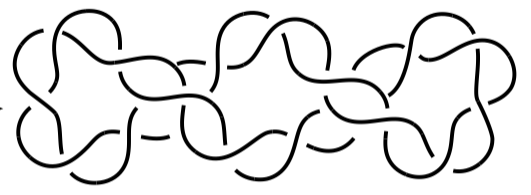

Structure is requested to be circular:
	Excess twist per base to make ends meet: 0.76 degrees
	New twist angle per base pair: 35.04 

Random sequence: CGAAGTTGAATTACGCCTGTACGGGCCCCAGCAATTAGCCGAAACTCTTCCCTTCTCGAGGAAATCAATCTAAGCTGACCAAGCTCACACCCGAGCTCTTCAGCTCTCGCCGCATTGCCCGGAATTTACAGAAACCATTGATTGGAACATCTGCTTAGGTTCCACCTCAGACTGCCATCCCACGGCCTGTTAACTGAAGGCACTCTGCCTGCCAATCATAGCCATA 

Number of base pairs is 226 that fit along the spline.


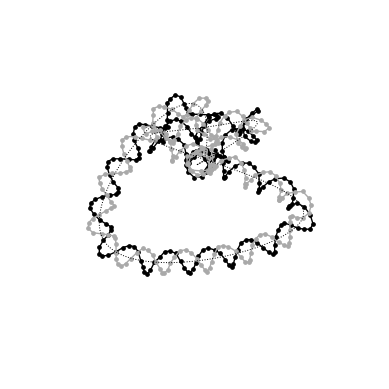

In [26]:
control_points = np.array([[0,0,0],[3,-3,3],[3,3,3],[0,0,3],[-3,-3,3],[6,6,-6], [-6,-6,-6],[-3,3,3],[0,0,0]])
closed_spline2 = mdna.make(control_points=control_points, circular=True)
n_bp = closed_spline2.n_bp
print(f'Number of base pairs is {n_bp} that fit along the spline.')
closed_spline2.draw()

### Creating Circular DNA Structures

Generate a circular DNA structure of 200 base pairs. Such structures are commonly known as minicircles. Visualize with a molecular viewer. 

In [27]:
dna = mdna.make(n_bp=200, circular=True)
dna.save_pdb('./minicircle_200bp')
view(dna)

Random sequence: CGCCATGGAGCACCAGTCTAATTCAGGGTATAACTGGACGCTTTAATGCCGTTAAAAACTCCAAGGCTAGTTACGCCGCATAGGTCCTCACTTATATGGACGGAATACGTCCTTACCGCCAAGAGCAACTGAGGTATTACTTAATATTGTGGGACAATTCCGAGAGACCCAGACGAGCGAAGGGGGACTCGGAGTTCCTC 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 200

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.09 degrees
	New twist angle per base pair: 34.2 



<IPython.core.display.Javascript object>

After generating the structure, you can minimize it to find a more energetically favorable conformation. mdna does this with a Monte Carlo (MC) simulation of a coarse-grained model: every base pair is a rigid body, connected to its neighbours by springs. The stiffness of the springs depends on the sequence and was derived from atomistic MD simulations. 

The MC simulation runs at a temperature (300 K by default). The result is therefore a typical conformation at that temperature, not the single lowest-energy one: minimize twice and you get two slightly different structures. 

In [28]:
# Minimize the DNA configuration
dna.minimize()

# See the final configuration
view(dna)

# Or save it to a file
dna.save_pdb('./minimized_minicircle_200bp')

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 2.0 
temperature = 300
Circular: True


####################################
Initiating Excluded Volume...
EV_bead mismatch: including additional boundary checks.

######################################
#### INITIALIZING EXCLUDED VOLUME ####
######################################
 Excluded Volume Beads: 
   number of EV beads: 29
   bp per EV bead:     7
   Effective size:     3.57
   Exclusion distance: 4.0
######################################


<IPython.core.display.Javascript object>

### Modifying Linking Number
Change the linking number by underwinding or overwinding the DNA using the `dLk` parameter. The linking number Lk is a topological property: it does not change during minimization. What can change is how Lk is divided over twist (Tw) and writhe (Wr), since Lk = Tw + Wr. Writhe changes slowly, so use `equilibrate_writhe=True` to keep the minimization running until the writhe has settled too.

In [29]:
dna = mdna.make(n_bp=200, circular=True, dLk=8)
dna.describe()
print('Lk before minimization [Lk, writhe, twist]:', dna.get_linking_number())

# Minimize the DNA configuration
dna.minimize(equilibrate_writhe=True)
print('Lk after minimization [Lk, writhe, twist]:', dna.get_linking_number())
dna.save_pdb('./minimized_minicircle_200bp_dLK8')

view(dna)

Random sequence: TTGTGCATATGAGGGGCATAAATTGTAATACCTAAAGACCCTTTTACATTCCTAGTCAGAAGGATCACGTTTAGAGCAATGCGGTCAGTGCGACCGAAGATAGTTCGAATAAATTCGATGATGTCACTCGTATCCACTCCGCGCATCATGGGCGCGACCTAGGACGAACAGCGATGGTCAGGTTCCGCTGGCATCGAACT 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 200

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.09 degrees
	New twist angle per base pair: 34.2 

Adjusting twist to match ΔLk = 8
	Current twist number (Tw₀): 19.00
	Computed writhe (Wr):        0.00
	Target twist number (Tw):    27.00
	Resulting Lk = Tw + Wr:      27.00
	Old twist angle per bp:      34.20°
	New twist angle per bp:      48.60°

Circular DNA structure with 200 base pairs
Sequence: TTGTGCATATGAGGGGCATAAATTGTAATACCTAAAGACCCTTTTACATTCCTAGTCAGAAGGATCACGTTTAGAGCAATGCGGTCAGTGCGACCGAAGATAGTTCGAATAAATTCGATGAT

E1 = 1455.73 kT
E2 = 1223.11 kT
wr_equi=False
wr1 = 0.87
wr2 = 2.13


E = 1189.02 kT
E_num_below=0
wr = 2.22
wr_num_below=0


E = 1209.77 kT
E_num_below=1
wr = 2.22
wr_num_below=0


E = 1212.47 kT
E_num_below=2
wr = 2.29
wr_num_below=0


E = 1220.69 kT
E_num_below=3
wr = 2.17
wr_num_below=1


wr = 2.13
wr_num_below=2


wr = 2.11
wr_num_below=3
Lk after minimization [Lk, writhe, twist]: [27.          2.08323804 24.91676196]


<IPython.core.display.Javascript object>

In [30]:
# For comparison: the same minicircle with dLk = 0
dna0 = mdna.make(n_bp=200, circular=True)
print('Lk before minimization [Lk, writhe, twist]:', dna0.get_linking_number())

dna0.minimize()
print('Lk after minimization [Lk, writhe, twist]:', dna0.get_linking_number())

Random sequence: CGGAAGCCAGAGTCCAAGCTGCACAATGCCAACACTCTGGATTTGCCCCTTCTCAGGACCGTAAAGAGTTCGTATTTACGTATCCATTTAGCGAACGCTAGCATTCGCGGGATGACCTACCCACTTGACGCCCTCGACTTGCAAAGTGCCTGAACTTCGGTTTGGGGATACATGGCGGATTGGATAAGTTCAGAAAGAGC 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 200

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.09 degrees
	New twist angle per base pair: 34.2 

Lk before minimization [Lk, writhe, twist]: [19.  0. 19.]
Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 2.0 
temperature = 300
Circular: True
####################################
Initiating Excluded Volume...
EV_bead mismatch: including additional boundary checks.

######################################
#### INITIALIZING EXCLUDED VOLUME ####
################

Lk after minimization [Lk, writhe, twist]: [19.         -0.09066077 19.09066077]


### Do it yourself!

Make new cells and use the code provided above as inspiration for the following questions:

a. Visualize the ideal and the minimized DNA minicircle of 200 base pairs. 

b. Use the structures you generated in the cells above to explain the difference between dLk = 0 and dLk = 8. 

For visualization, use `view(dna)`, or a molecular viewer for the pdb file you can save with `dna.save_pdb()`.

**Answers**

a. The ideal minicircle is a perfect circle. After minimization it is no longer perfectly round: the MC simulation runs at 300 K, so the circle shows thermal bending.

b. Lk = Tw + Wr. With dLk = 0 almost all of the linking number is twist (Wr close to 0), and the circle stays roughly flat. With dLk = 8 the DNA has 8 extra turns. Right after building, all of these are twist (Lk = Tw = 27, Wr = 0). Overwinding costs elastic energy, so during minimization part of the extra twist turns into writhe: the circle bends out of its plane, which is supercoiling. Lk stays exactly 27, while Wr grows to about 2 and Tw drops by the same amount (the exact numbers vary between runs).

Note: for a closed circle, Lk has to be a whole number. 200 bp at 10.5 bp per turn is 19.05 turns, so mdna adjusts the twist slightly to make exactly 19 turns. That is the "Excess twist per base to make ends meet" in the output of `make()`.

### Defining Complex Custom Shapes
Define intricate shapes by specifying control points manually. The points are used to fit a B-spline that goes through each of these points. Note, the minimum number of `control_points` to fit a spline through is 4.

In [31]:
control_points = np.array([[15,5,5],[3,3,3],[2,2,2],[0,0,0]])
dna1 = mdna.make(n_bp=50, control_points=control_points)
dna1.save_pdb('./dna1')
dna1.describe()

dna2 = mdna.make(n_bp=100, circular=True)
dna2.save_pdb('./dna2')
dna2.describe()


Random sequence: ATGTACCGAGGGACGAGCTGGTTGTCTTATTTTAGAGAAATAAAGCCCTC 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 50

DNA structure with 50 base pairs
Sequence: ATGTACCGAGGGACGAGCTGGTTGTCTTATTTTAGAGAAATAAAGCCCTC
Trajectory: <mdtraj.Trajectory with 1 frames, 2050 atoms, 100 residues, without unitcells>
Frames:  (50, 1, 4, 3)
Random sequence: GTACACCTATAGACTTTTAAATCAATTGCACCTGCAGAATTACTTGACGACTACGGAGTTCCCATATCTTCCGGATGTATTAGCCTTCGCGAATGCAAAG 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 100

Structure is requested to be circular:
	Excess twist per base to make ends meet: 1.71 degrees
	New twist angle per base pair: 36.0 

Circular DNA structure with 

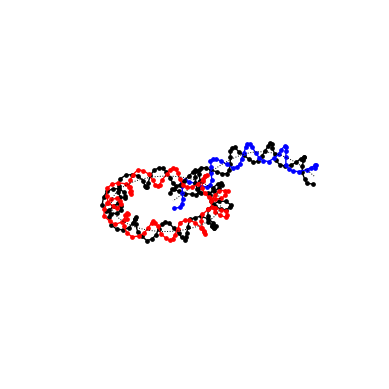

In [32]:
#visualize the two structures with matplotlib
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

dna1.draw(ax=ax, lw=1, color_anti='blue')
dna2.draw(ax=ax, color_anti='red')

## Knotted DNA

Now you are ready to generate a DNA structure shaped in the form of a knot! 

To do so you need to define the knot as a parametric function. Below the parametric functions of the trefoil knot and the figure-eight knot are provided. You can add a new function with the parametric function of another knot. See https://mathcurve.com/courbes3d.gb/noeuds/noeud.shtml for an overview of knots and several parametric representations. 

Note that to generate a DNA structure from the spline, there needs to be sufficient room for the base pairs. You can tune this with the `scaling` parameter in the parametric functions. The more base pairs you include, the longer it takes to generate a structural model. 

In [33]:
def parametric_trefoil(t, scaling=5):
    x = scaling*(np.sin(t)) + scaling*(2*np.sin(2*t)) 
    y = scaling*(np.cos(t)) - scaling*(2*np.cos(2*t))
    z = scaling*(-np.sin(3*t))
    return x, y, z

def parametric_figure_eight(t, scaling=1/32):
    x = scaling*32*np.cos(t) - scaling*51*np.sin(t) - scaling*104*np.cos(2*t) - scaling*34*np.sin(2*t) + scaling*104*np.cos(3*t) - scaling*91*np.sin(3*t)
    y = scaling*94*np.cos(t)+ scaling*41*np.sin(t) + scaling*113*np.cos(2*t) - scaling*68*np.cos(3*t) - scaling*124*np.sin(3*t)
    z = scaling*16*np.cos(t) + scaling*73*np.sin(t) - scaling*211*np.cos(2*t) - scaling*39*np.sin(2*t) - scaling*99*np.cos(3*t) - scaling*21*np.sin(3*t)
    return x, y, z

# define your own knot, for example a torus knot: the curve winds p times around
# the axis of a torus and q times through its hole. p=2, q=5 is the cinquefoil knot.
def parametric_another_knot(t, scaling=5, R=2, r=1, p=2, q=5):
    x = scaling*(R + r*np.cos(q*t))*np.cos(p*t)
    y = scaling*(R + r*np.cos(q*t))*np.sin(p*t)
    z = scaling*r*np.sin(q*t)
    return x, y, z

In [34]:
t = np.linspace(0, 2 * np.pi, 50)  # 0 to 2π with 50 points
x, y, z = parametric_trefoil(t)
control_points = np.array([x, y, z]).T  # Create a (n_points, 3) array

Text(0.5, 0, 'Z')

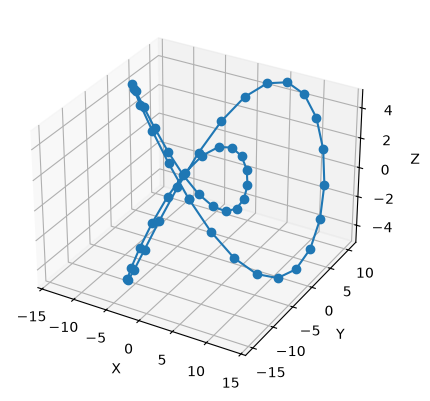

In [35]:
# plot the control points
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(*control_points.T, 'o-')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

In [36]:
knot = mdna.make(control_points=control_points, circular=True) # Use `circular=True` to close the DNA knot. 
n_bp = knot.n_bp
print(f'Number of base pairs is {n_bp} that fit along the spline.')

view(knot)

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.24 degrees
	New twist angle per base pair: 34.04 

Random sequence: ATCGCCACGGATCTGTACTGAGAGGACGTATCACTCAGTCGAGTTTGAAGCGACACGCCCCTCTTTACAAACATCATCATAGTAGAAAGGGGTTCAAATCGTGCATGGGACTGGTCTTTAACGATTCCCTTGAATTATACTACACGCACCAATTTACGTCGCATTACCCCGGCCGGCTCAGATCACTATTCCACCTACTCACCCCTCTACGGATTTTACAGTCGGCACCGCAGCGGGCGATTCAGTAACAGAATATCCGGGGATGGCGTTTTGCTATGATGGACCCCACGAGTGACACTCTCTTCGGACCGGCCCAACTGGGCGCCATATCATGTCGATGGGATCGCTGAATGTCGGCTTGCAGGTGTTTCTAAATCCACCCTCAGCGCGAGTGGGAGTTCACTCACAACTCCCCGGCGCAGC 

Number of base pairs is 423 that fit along the spline.


<IPython.core.display.Javascript object>

### Do it yourself

Generate other knots. For example, the figure-eight: `control_points = np.array(parametric_figure_eight(np.linspace(0, 2 * np.pi, 50))).T`, then build the DNA with `mdna.make(control_points=control_points, circular=True)`. See https://mathcurve.com/courbes3d.gb/noeuds/noeud.shtml for an overview of knots and several parametric representations. 

In [37]:
# figure-eight knot
control_points = np.array(parametric_figure_eight(np.linspace(0, 2 * np.pi, 50))).T
figure_eight = mdna.make(control_points=control_points, circular=True)
print(f'Number of base pairs is {figure_eight.n_bp} that fit along the spline.')
view(figure_eight)
figure_eight.save_pdb('./figure_eight_knot')

# cinquefoil knot, the (2, 5) torus knot
control_points = np.array(parametric_another_knot(np.linspace(0, 2 * np.pi, 100))).T
cinquefoil = mdna.make(control_points=control_points, circular=True)
print(f'Number of base pairs is {cinquefoil.n_bp} that fit along the spline.')
view(cinquefoil)
cinquefoil.save_pdb('./cinquefoil_knot')

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.25 degrees
	New twist angle per base pair: 34.04 

Random sequence: CAACTGTGTGGTCAACGCAGTTCTTGCGGTCAGAAGTTTATGACAAATAAATTTCATCAGAGCCACGACAATGAGCCCGGAAAGTCAGTAGCATTGGACCTCGCCTGGCATCTAAGTCTCGTATGTCGAGCTGGCGAAACTCGGAAAGCCTGTTCAGTAATAGGAGAAGGGTTTCGTCTACACCAAGTCACGACTCAAGGCCTTTTGAAGCAGGCTTCGGAGCATCCAGAGTTCATGCTGCTACCAACAGACTAAGCTTCAAGTATCGTGAAATTGGGCTACCGGGCATGAATACTTGGCTCACTTTGCTGAAGATGCGAGTCCGTGAAGACCGTCACCCTTACTTCTG 

Number of base pairs is 349 that fit along the spline.


<IPython.core.display.Javascript object>

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.09 degrees
	New twist angle per base pair: 34.2 

Random sequence: AGATCGGGAAGAAAAGCTTGAACGTATCGTTGAATGTCGTTCTCATAGAATAAGTCCAAAAATGGTCATAAATTCCGTGCTACGAAGATCCCTACCGCGTTTCTGTGTGCAATCGAGAGTTAATGTTTTCGAGCCACTAGCATTAGTCGCTGGTTTGCACGTCCTGCAAACCGAAGTAGCTATTTACTTCTCCGCGTGCTCCGCTCTAAGCTGCCGCTAAGTCTCCCCCTTCTATCAAAACTACACAGCAACGTCACTTGGGCTTGGGTCATTTATACACAATTATATAATAGCAAATAACATGTACGATGCTAAGATATGCTTTTAATTAATCGGTTAGATTCCAGTAAGCAATTGGTAGTTGCGTATAAAAGGTACTCGTACACGGGTAAATAATCTTCTCCAGAGTAGCCCCATCGTTTTAGCAATACAACTCTAGGCAACGGCGGGGATCGGTCGAGTTGAGGCACATCCCGGAGTCTCTGAACTTAGAGATGTGACCACCGGCCTGTCCTGGTCGACCAACTGAAAGGCTCCCTGTGAGCACTACGGGAGTCCAGTAAGGGAGTGGGATTTGCCGAATTTCCTCGGTGCCTCCGG 

Number of base pairs is 600 that fit along the spline.


<IPython.core.display.Javascript object>